**Tutorial Code by Amirhossein Ahrari YouTube:** https://www.youtube.com/@amirhosseinahrarigee

**Tutorial Video: PySTAC Tutorial-14: Sentinel-2 Crop Specific Segmentation using felzenszwalb algorithm in Python**

This code is part of a tutorial series on python eo programming techniques
presented on the Amirhossein Ahrari YouTube channel. You are free to use and modify
this code for academic and non-academic purposes. Don't forget to subscribe to
the Amirhossein Ahrari channel and follow the videos to support the instructor.

In [1]:
!pip install -q pystac-client

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.8/41.8 kB 623.0 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 117.3/117.3 kB 1.7 MB/s eta 0:00:00


In [2]:
from pystac_client import Client

In [3]:
catalog = Client.open(
    'https://earth-search.aws.element84.com/v1'
)

In [4]:
for collection in catalog.get_collections():
  print(collection.id)

sentinel-2-pre-c1-l2a
cop-dem-glo-30
naip
cop-dem-glo-90
landsat-c2-l2
sentinel-2-l2a
sentinel-2-l1c
sentinel-2-c1-l2a
sentinel-1-grd


In [5]:
roi = [48.820535, 31.949967, 48.845589, 31.971459]

In [6]:
search = catalog.search(
    collections = ['sentinel-2-c1-l2a'],
    bbox = roi,
    datetime = '2025'
)

In [7]:
items = search.item_collection()

/usr/local/lib/python3.13/dist-packages/pystac/extensions/storage.py:724: UserWarning: Could not parse bucket/account from href. The following assets were not migrated: ['red', 'green', 'blue', 'visual', 'nir', 'swir22', 'rededge2', 'rededge3', 'rededge1', 'swir16', 'wvp', 'nir08', 'scl', 'aot', 'coastal', 'nir09', 'cloud', 'snow', 'preview', 'granule_metadata', 'tileinfo_metadata', 'product_metadata', 'thumbnail']
  warnings.warn(


In [8]:
len(items)

175

In [11]:
items[0].properties['proj:code']

'EPSG:32639'

In [12]:
items[0].assets.keys()

dict_keys(['red', 'green', 'blue', 'visual', 'nir', 'swir22', 'rededge2', 'rededge3', 'rededge1', 'swir16', 'wvp', 'nir08', 'scl', 'aot', 'coastal', 'nir09', 'cloud', 'snow', 'preview', 'granule_metadata', 'tileinfo_metadata', 'product_metadata', 'thumbnail'])

In [13]:
!pip install -q stackstac
from stackstac import stack

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.3/64.3 kB 845.9 kB/s eta 0:00:00


In [14]:
layer_stack = stack(
    items,
    assets = ['nir','red','scl'],
    epsg = 32639,
    resolution = 10,
    bounds_latlon = roi
)

In [19]:
ds = (
    layer_stack
    .to_dataset('band')
    .drop_dims('band')
    .reset_coords(drop = True)
    .drop_attrs()
)

In [21]:
mask = ds.scl.isin([0,1,3,8,9,10,11]).astype(int)
ds_mask = ds[['nir','red']].where(mask == 0)

In [22]:
nir = ds_mask['nir']
red = ds_mask['red']
ndvi = (nir - red) / (nir + red)

In [23]:
ndvi_monthly = ndvi.resample(time = 'ME').max('time')

In [24]:
ndvi_mean = ndvi_monthly.mean(dim = 'time')

In [25]:
from dask.diagnostics import ProgressBar

In [27]:
import warnings
warnings.filterwarnings('ignore', category = RuntimeWarning)
import logging
logging.getLogger().setLevel(logging.ERROR)

In [28]:
with ProgressBar():
  ndvi_mean = ndvi_mean.compute()

[########################################] | 100% Completed | 186.34 s


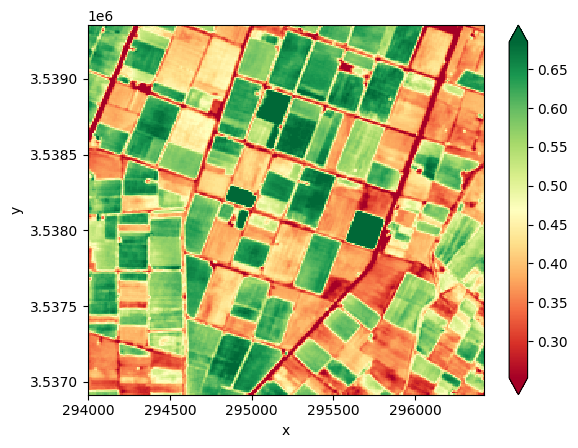

In [29]:
ndvi_mean.plot(
    robust = True,
    cmap = 'RdYlGn'
)

In [30]:
from skimage.segmentation import felzenszwalb

In [33]:
import xarray as xr

In [35]:
from scipy.ndimage import mean

In [56]:
labels = felzenszwalb(
    ndvi_mean.values,
    scale = 100,
    sigma = 0.1,
    min_size = 30,
    channel_axis = None
)

In [57]:
segments = xr.DataArray(
    labels,
    dims = ndvi_mean.dims,
    coords = ndvi_mean.coords
)

In [58]:
ndvi_mean_seg = mean(
    ndvi_mean,
    labels = segments,
    index = segments
)

ndvi_mean_seg = xr.DataArray(
    ndvi_mean_seg,
    dims = ndvi_mean.dims,
    coords = ndvi_mean.coords
)

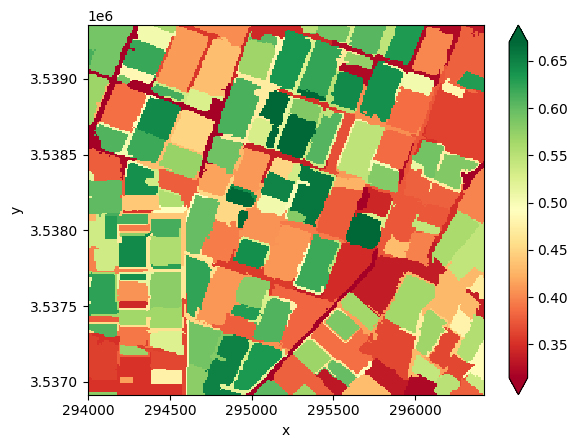

In [59]:
ndvi_mean_seg.plot(
    robust = True,
    cmap = 'RdYlGn'
)

In [43]:
import matplotlib.pyplot as plt

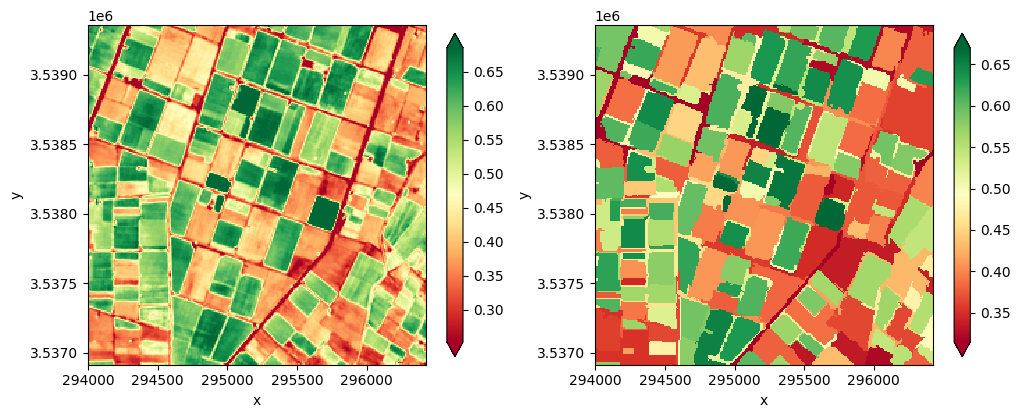

In [61]:
fig, ax = plt.subplots(1, 2, figsize = (12,12))

ndvi_mean.plot(
    ax = ax[0], robust = True, cmap = 'RdYlGn',
    cbar_kwargs = {'shrink': 0.35}
)

ndvi_mean_seg.plot(
    ax = ax[1], robust = True, cmap = 'RdYlGn',
    cbar_kwargs = {'shrink': 0.35}
)

for a in ax:
  a.set_aspect('equal', adjustable = 'box')

plt.savefig('ndvi_seg.png', dpi = 360, bbox_inches = 'tight')